## Detect functional groups in MOFs
In this notebook, we will use mofography to detect sepecifc functional groups in MOFs. We will then extend this to look for functional groups in a database of MOFs such as the CoRE MOF database. 
### Algorithm 

Under the hood, mofography uses a graph-based approach to detect functional groups. The algorithm is called subgraph isomorphism and is a well-known problem in computer science. The algorithm is implemented in the [networkx](https://networkx.github.io/) package. Detection occurs based on element and bond types. The source code is in `analyze.py` in the mofography package.

### Steps 

- Load the MOF into ASE
- Load the function group as SMARTS
- Convert both to networkx graphs, via. RDKit
- Detect the functional group in the MOF using subgraph isomorphism
- Make separate atoms object for just selected atoms and bonds in the MOF
- Visualize just hat to confirm


### Functional groups
In this example we are just looking for COO groups, which are extremely common in MOFs. If you want to look for other functional groups, please use SMARTS notation to define the functional group. And some explanation of SMARTS is provided later. 

## Imports
Import the necessary packages.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import sys
path_to_mgr= Path('c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography_general/mofography')
sys.path.append(str(path_to_mgr))
import mofography as mgr
import pickle
from ase.io import read
import networkx as nx 
from tqdm import tqdm
import plotly.graph_objects as go

## Grab a dataset
Either grab it from MOFDB or if you have pre saved file read it in to a pandas dataframe.

To grab from MOFDB use this one as a mofography example for setting ranges. This takes a long time, so it's better if you do in once and save the dataframe for future use as a feather or pickle file.  

In [2]:
df = mgr.get_data_from_mofdb(params={'vf_min': 0.7, 'vf_max': 0.75,'lcd_min':12,'lcd_max':14, 'database':'CoREMOF 2019'})

Output()

c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\mofography\data.py:126: RuntimeWarning: coroutine 'ClientSession.close' was never awaited
  session.close()
Unclosed client session
client_session: <aiohttp.client.ClientSession object at 0x00000212DBFD7460>
Unclosed connector
connections: ['[(<aiohttp.client_proto.ResponseHandler object at 0x00000212DBFE7580>, 977828.937)]']
connector: <aiohttp.connector.TCPConnector object at 0x00000212DBFD7220>


TO read from saved file, for e.g. `.feather` file, use this example: 

In [3]:
# df  = pd.read_feather(path_to_dataset) # put your path here

Let's look at the first 10 MOFs in the dataset.

In [4]:
df.head(10)

,id,mofid,mofkey,hashkey,name,void_fraction,surface_area_m2g,surface_area_m2cm3,pld,lcd,...,pore_size_distribution,database,batch_number,elements,cif,url,adsorbates,heats,isotherms,mofdb_version
0,173921,None,None,c83f3cb36e0bdad5ead5471ad8a1b89225c7fb6f5504e1...,acs.inorgchem.6b02413_ic6b02413_si_002_clean,0.7400,2730.07,2195.74,6.88163,13.3773,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 27.546\n_cel...,/mofs/173921.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
1,173987,None,None,79e851559c2af43b378a63b4b468ccadf6804dd517e3d2...,AGABIU_clean,0.7402,2773.67,1794.91,10.82740,12.5710,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 18.605\n_cel...,/mofs/173987.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
2,174106,None,None,70afd8ccd600fd030504ce0c97919d5110cebead9459fa...,ANOMOG_clean,0.7198,2698.05,2116.78,5.50166,12.8003,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 32.461\n_cel...,/mofs/174106.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
3,174196,None,None,29a7e26bd38915ad1c147d2088d54906bffb579ec86021...,ASINEX_clean,0.7014,2801.34,1848.81,7.27061,12.5357,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 74.91\n_cell...,/mofs/174196.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
4,174197,None,None,e2eb2e4b54ff5bc14d64019746578c77fe71402d8a8eaa...,ASINIB_clean,0.7130,2773.85,1847.56,7.22634,12.4005,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 75.033\n_cel...,/mofs/174197.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
5,174278,None,None,5842c228d724798a90bc4599997bd3d766e1f4a42995c9...,AVIVUW_clean,0.7162,2491.03,1817.90,6.91892,12.0408,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 22.963\n_cel...,/mofs/174278.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
6,174294,None,None,c2eeca1b812f60d10f8e08b7e6d31126b754d4039c9c76...,AWASEY_clean,0.7186,1646.54,1906.22,7.26209,12.0509,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 30.332\n_cel...,/mofs/174294.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
7,174429,None,None,594e605ccc2636780d8a4d1047ec910d12c302481211a5...,BAZJET_clean,0.7420,3450.50,2143.77,12.10120,13.3702,...,None,CoREMOF 2019,41,[],data_BAZJET_clean\n_audit_creation_date ...,/mofs/174429.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
8,174549,None,None,2e72bfca4ff457bde255581761a55cc102f95820e003f4...,BINCUY_manual,0.7246,3760.71,2196.14,8.62623,13.3117,...,None,CoREMOF 2019,41,[],data_BINCUY_clean_b\n_audit_creation_date ...,/mofs/174549.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db
9,174550,None,None,47936b6cf988f16f2f51b47970dad99122035c3190cd0d...,BINDAF_manual,0.7212,3638.73,2185.42,8.49712,13.1432,...,None,CoREMOF 2019,41,[],data_BINDAF_clean_b\n_audit_creation_date ...,/mofs/174550.json,"[{'id': 80, 'InChIKey': 'IJGRMHOSHXDMSA-UHFFFA...",[],"[{'batch_number': 41, 'adsorbates': [{'id': 80...",dc8a0295db


Convert them to ASE atoms objects. DO it once and save it as a pickle file for future use. 

In [5]:
core_atoms = mgr.atoms_from_mofdb_df(df)
# pickle.dump(core_atoms, open('core_atoms.pkl','wb'))

  5%|▌         | 7/138 [00:03<00:51,  2.52it/s]c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\io\cif.py:401: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(
100%|██████████| 138/138 [00:23<00:00,  5.92it/s]
c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\mofography\data.py:166: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  return np.array(atoms_list)


Or if you have it already, load it up here: 

In [6]:
# core_atoms = pickle.load(open('./core_atoms_list.pkl','rb'))

Let's pick one material and test our methodology

In [7]:
mat_atoms = core_atoms[1]

## How to specify functional moeties? 

Functional moieties, also known as functional groups, can be specified using SMARTS (SMiles ARbitrary Target Specification) notation. SMARTS is a language that allows you to describe molecular patterns. It is used extensively in cheminformatics to search for structural patterns within datasets of molecules.

For example, the SMARTS pattern for a carboxylate group is `[C;X3](-[O;X1])-[O;X1]`.

Here's a breakdown of this pattern:

- `[C;X3]`: This matches a carbon atom (`C`) with three connections (`X3`). The semicolon (`;`) is used to combine different conditions, so `C;X3` matches a carbon atom with exactly three bonds.

- `(-[O;X1])`: This matches an oxygen atom (`O`) with one connection (`X1`), i.e., a single bond. The parentheses are used to group atoms and bonds that should be considered as a unit. The `-` inside the parentheses indicates a single bond.

- `-[O;X1]`: This matches another oxygen atom with a single bond. The `-` outside the parentheses indicates that this oxygen atom is bonded to the previously matched atom (the carbon atom).

So, the SMARTS pattern `[C;X3](-[O;X1])-[O;X1]` matches a carbon atom with three bonds, one of which is to an oxygen atom, and another of which is to another oxygen atom. This is the pattern for a carboxylate group.


In [8]:
mat_atoms = core_atoms[1]
functional_groups = {
    'carboxylate': '[C;X3](-[O;X1])-[O;X1]',
    # Add more functional groups here
}
matches = mgr.find_functional_groups(mat_atoms, functional_groups)


Let's look at the detected atoms for carboxylate group in the material, if any. 

In [10]:
matches

{'carboxylate': [{7: 0, 1: 1, 2: 2},
  {7: 0, 2: 1, 1: 2},
  {15: 0, 9: 1, 10: 2},
  {15: 0, 10: 1, 9: 2},
  {23: 0, 17: 1, 18: 2},
  {23: 0, 18: 1, 17: 2},
  {31: 0, 25: 1, 26: 2},
  {31: 0, 26: 1, 25: 2},
  {39: 0, 33: 1, 34: 2},
  {39: 0, 34: 1, 33: 2},
  {47: 0, 41: 1, 42: 2},
  {47: 0, 42: 1, 41: 2},
  {55: 0, 49: 1, 50: 2},
  {55: 0, 50: 1, 49: 2},
  {63: 0, 57: 1, 58: 2},
  {63: 0, 58: 1, 57: 2},
  {71: 0, 65: 1, 66: 2},
  {71: 0, 66: 1, 65: 2},
  {79: 0, 73: 1, 74: 2},
  {79: 0, 74: 1, 73: 2},
  {87: 0, 81: 1, 82: 2},
  {87: 0, 82: 1, 81: 2},
  {95: 0, 89: 1, 90: 2},
  {95: 0, 90: 1, 89: 2}]}

## Visualize
Now, let's use mofography to visualize and confirm that the correct atoms are detected. 

In [11]:
mgr.update_with_covalent_bonds(mat_atoms)

Atoms(symbols='C72Li18N12Ni10O54', pbc=True, cell=[[18.605, 0.0, 0.0], [-9.302499999999997, 16.11240263740948, 0.0], [0.0, 0.0, 14.904]], image of=..., spacegroup_kinds=...)

In [14]:
# mat_atoms = read(path_to_cif)
mat_atoms = core_atoms[1]
mat_updated =mgr.update_with_covalent_bonds(mat_atoms)
functional_groups = {
    'carboxylate': '[C;X3](-[O;X1])-[O;X1]',
    # Add more functional groups here
}
matches = mgr.find_functional_groups(mat_atoms, functional_groups)
matching_indices = np.concatenate([list(m.keys()) for m in matches['carboxylate']])
# Create a list of atoms that match the indices
# matching_atoms = []
# for group, indices_list in matches.items():
#     for indices in indices_list:
#         matching_atoms.extend([mat_updated[i] for i in indices.keys()])

frame_subset_trace = mgr.plot_subset_of_atoms(mat_atoms, subset=matching_indices)


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning: Use get_global_number_of_atoms() instead
  warnings.warn('Use get_global_number_of_atoms() instead',


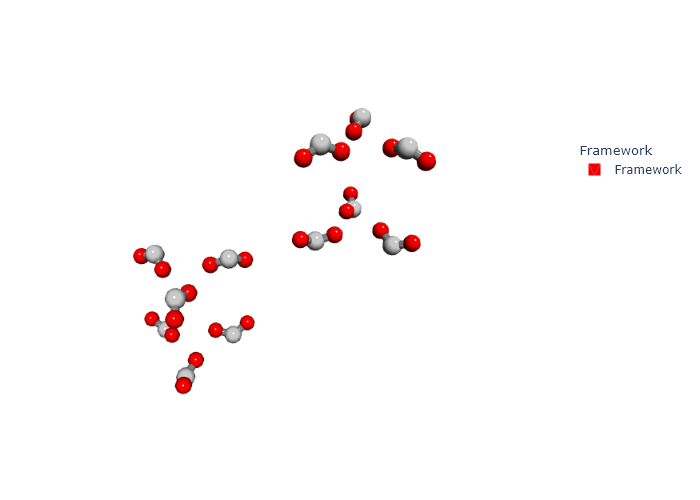

In [16]:
go.Figure(data=[*frame_subset_trace], layout=mgr.white_layout).show(renderer='png')    

##  Bonus: Visualize the whole material if you're curious

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning:

Use get_global_number_of_atoms() instead

c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\mofography\analyze.py:402: VisibleDeprecationWarning:

Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.



No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\mofography\visualize.py:768: UserWarning:

Optimal rotation is not uniquely or poorly defined for the given sets of vectors.



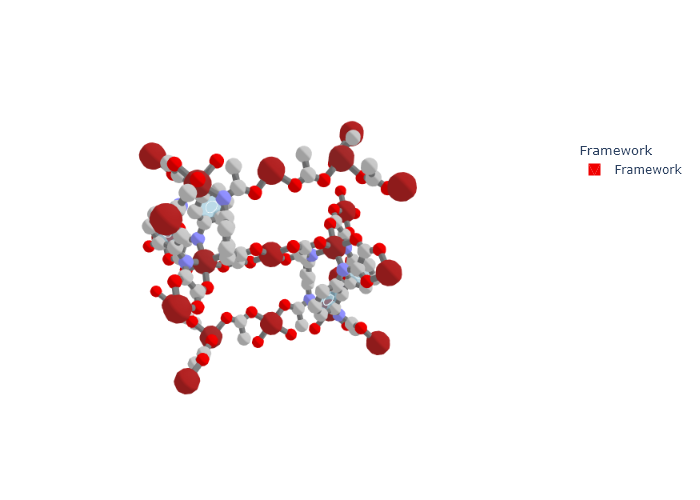

In [17]:
frame_trace = mgr.plot_framework_as_mesh(mat_updated)
fig  = go.Figure(data=frame_trace)
fig.update(layout=mgr.white_layout)
fig.show(renderer='png')

## Apply to CoRE MOFs

Now we have to apply the functional group detection to a list of coremof atoms, that we have precompiled as shown in the beginning of the notebook. We wil use a simple try: except in a for loop for this so that in case some structures fail due to large size or some other reason, we can still screen the rest of the structures without fail.

it is going to take a few 3-5 minutes. 


(PS: If you ahve multiple functional groups, please screen for them all at the same time, not one by one.😂)

In [18]:
functional_groups = {
    'carboxylate': '[C;X3](-[O;X1])-[O;X1]',
    # Add more functional groups here
}
matches_list = []
for atoms in tqdm(core_atoms):
    try:
        matches_list.append(mgr.find_functional_groups(atoms, functional_groups))
    except:
        matches_list.append(None)


 20%|██        | 28/138 [00:00<00:03, 34.88it/s][20:49:21] Maximum BFS search size exceeded.
This is likely due to a highly symmetric fused ring system.
 43%|████▎     | 60/138 [00:02<00:02, 29.17it/s][20:49:23] Maximum BFS search size exceeded.
This is likely due to a highly symmetric fused ring system.
 49%|████▊     | 67/138 [00:02<00:03, 20.59it/s][20:49:23] Maximum BFS search size exceeded.
This is likely due to a highly symmetric fused ring system.
100%|██████████| 138/138 [00:05<00:00, 24.71it/s]


In [19]:
matches_list

[{'carboxylate': [{568: 0, 24: 1, 264: 2},
   {568: 0, 264: 1, 24: 2},
   {571: 0, 269: 1, 29: 2},
   {571: 0, 29: 1, 269: 2},
   {574: 0, 274: 1, 34: 2},
   {574: 0, 34: 1, 274: 2},
   {577: 0, 39: 1, 279: 2},
   {577: 0, 279: 1, 39: 2},
   {580: 0, 284: 1, 44: 2},
   {580: 0, 44: 1, 284: 2},
   {583: 0, 289: 1, 49: 2},
   {583: 0, 49: 1, 289: 2},
   {586: 0, 294: 1, 54: 2},
   {586: 0, 54: 1, 294: 2},
   {589: 0, 59: 1, 299: 2},
   {589: 0, 299: 1, 59: 2},
   {592: 0, 64: 1, 324: 2},
   {592: 0, 324: 1, 64: 2},
   {595: 0, 329: 1, 69: 2},
   {595: 0, 69: 1, 329: 2},
   {598: 0, 74: 1, 334: 2},
   {598: 0, 334: 1, 74: 2},
   {601: 0, 339: 1, 79: 2},
   {601: 0, 79: 1, 339: 2},
   {604: 0, 304: 1, 84: 2},
   {604: 0, 84: 1, 304: 2},
   {607: 0, 89: 1, 309: 2},
   {607: 0, 309: 1, 89: 2},
   {610: 0, 314: 1, 94: 2},
   {610: 0, 94: 1, 314: 2},
   {613: 0, 99: 1, 319: 2},
   {613: 0, 319: 1, 99: 2},
   {616: 0, 104: 1, 464: 2},
   {616: 0, 464: 1, 104: 2},
   {619: 0, 109: 1, 469: 2},
  

From here I'll leave it to you to do what ever post processing you want. 